# Euler–Maruyama method for solve SDEs


Our main in this proyect is to learn foundations of Stochastic Analysis and how to implement this in python (numpy + mathplotlib)

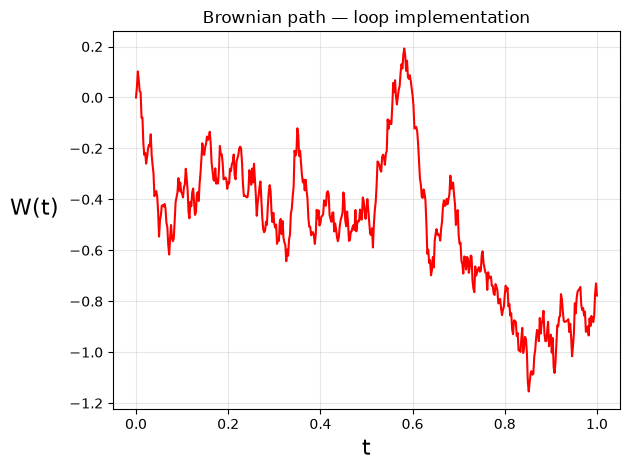

In [22]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng()

T = 1.0
N = 500
dt = T / N

t = np.linspace(0, T, N + 1) #N+1 evenly spaced points in [0,T]
dW = np.zeros(N)
W = np.zeros(N + 1)  # Includes W(0) = 0

dW = np.sqrt(dt) * rng.standard_normal(N)
W = np.concatenate(([0.0], np.cumsum(dW)))

# plt.figure(figsize=(9, 4))
plt.plot(t, W, "r-")
plt.xlabel("t", fontsize=16)
plt.ylabel("W(t)", fontsize=16, rotation=0, labelpad=25)
plt.title("Brownian path — loop implementation")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Maximum error over the time grid: 0.094360


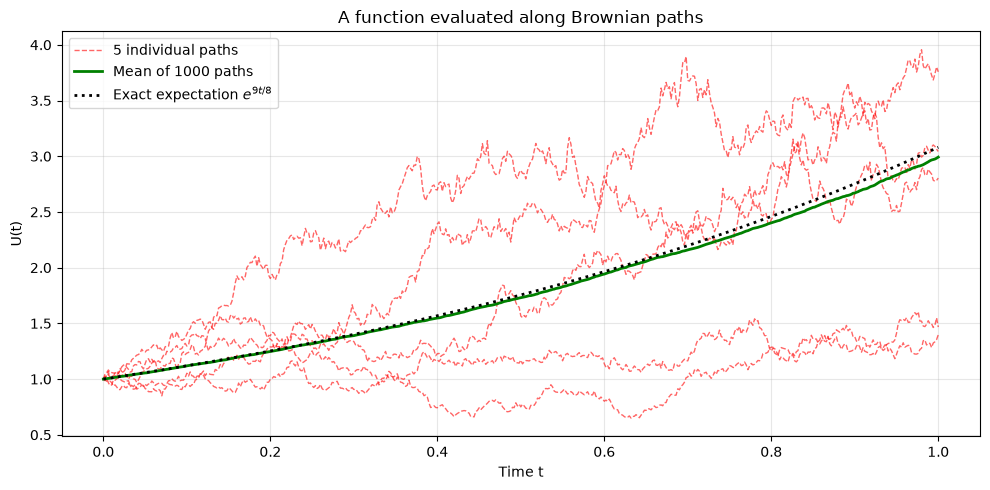

In [23]:
T_paths = 1.0
N_paths = 500       # Number of time steps
M = 1000      # Number of independent paths
dt_paths = T_paths / N_paths

t_paths = np.linspace(0, T_paths, N_paths + 1)

# Each row contains the increments of one Brownian path
dW_paths = np.sqrt(dt_paths) * rng.standard_normal((M, N_paths))

# Include W_paths(0) = 0 for every path
W_paths = np.zeros((M, N_paths + 1))
W_paths[:, 1:] = np.cumsum(dW_paths, axis=1)

# Evaluate U(t) = exp(t_paths + W(t)/2) along every path
U = np.exp(t_paths + 0.5 * W_paths)

# Average across paths at each time
U_mean = np.mean(U, axis=0)

# Exact expectation
exact_mean = np.exp(9 * t_paths / 8)

# Maximum absolute error over the time grid
averr = np.max(np.abs(U_mean - exact_mean))
print(f"Maximum error over the time grid: {averr:.6f}")

fig, ax = plt.subplots(figsize=(10, 5))

# Show five individual paths
for m in range(5):
    ax.plot(
        t_paths, U[m],
        color="red",
        linestyle="--",
        linewidth=1,
        alpha=0.6,
        label="5 individual paths" if m == 0 else None
    )

ax.plot(
    t_paths, U_mean,
    color="green",
    linewidth=2,
    label=f"Mean of {M} paths"
)

ax.plot(
    t_paths, exact_mean,
    color="black",
    linestyle=":",
    linewidth=2,
    label=r"Exact expectation $e^{9t/8}$"
)

ax.set(
    xlabel="Time t",
    ylabel="U(t)",
    title="A function evaluated along Brownian paths"
)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [24]:
# Use W, dW, T and dt from the first simulation cell.
# Run that cell again to generate a new path.

# Ito: evaluate the integrand at each left endpoint
ito = np.sum(W[:-1] * dW)

# Sample Brownian values at the temporal midpoints,
# conditional on the already simulated endpoints
Z = rng.standard_normal(dW.size)
W_mid = 0.5 * (W[:-1] + W[1:]) + 0.5 * np.sqrt(dt) * Z

# Stratonovich: evaluate at the temporal midpoints
strat = np.sum(W_mid * dW)

# Exact integrals for this Brownian realization
ito_exact = 0.5 * (W[-1]**2 - T)
strat_exact = 0.5 * W[-1]**2

ito_error = abs(ito - ito_exact)
strat_error = abs(strat - strat_exact)

print(f"Ito approximation:          {ito:.6f}")
print(f"Ito exact value:            {ito_exact:.6f}")
print(f"Ito absolute error:         {ito_error:.6f}")
print()
print(f"Stratonovich approximation: {strat:.6f}")
print(f"Stratonovich exact value:   {strat_exact:.6f}")
print(f"Stratonovich absolute error:{strat_error: .6f}")

Ito approximation:          -0.214829
Ito exact value:            -0.197875
Ito absolute error:         0.016954

Stratonovich approximation: 0.310474
Stratonovich exact value:   0.302125
Stratonovich absolute error: 0.008349


Terminal absolute error: 0.033750


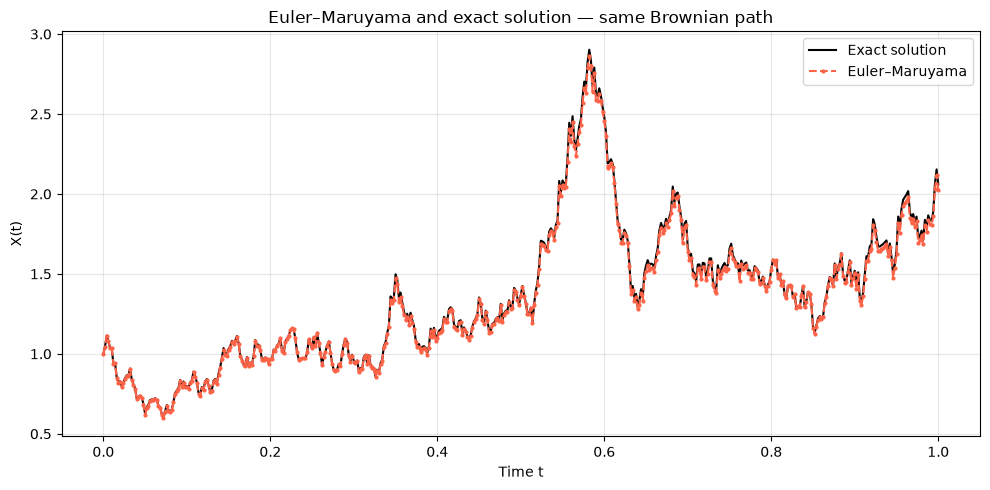

In [29]:
# Model parameters: dX = drift * X dt + volatility * X dW
drift = 2.0
volatility = 1.0
X0 = 1.0

# Reuse the Brownian path from the first simulation cell
N_fine = len(dW)
t_fine = np.arange(N_fine + 1) * dt

# Exact solution at the fine grid points
X_exact = X0 * np.exp(
    (drift - 0.5 * volatility**2) * t_fine
    + volatility * W
)

# Euler–Maruyama uses one step per R Brownian increments
R = 1

if N_fine % R != 0:
    raise ValueError("The number of Brownian increments must be divisible by R.")

dt_em = R * dt
n_steps = N_fine // R
t_em = t_fine[::R]

# Each row contains R consecutive increments of the same path
dW_em = dW.reshape(n_steps, R).sum(axis=1)

X_em = np.empty(n_steps + 1)
X_em[0] = X0

for j in range(n_steps):
    X_em[j + 1] = (
        X_em[j]
        + drift * X_em[j] * dt_em
        + volatility * X_em[j] * dW_em[j]
    )

# Compare both solutions at the terminal time
terminal_error = abs(X_em[-1] - X_exact[-1])
print(f"Terminal absolute error: {terminal_error:.6f}")

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(t_fine, X_exact, color="black", label="Exact solution")
ax.plot(
    t_em, X_em,
    color="tomato",
    linestyle="--",
    marker=".",
    markersize=4,
    label="Euler–Maruyama"
)

ax.set(
    xlabel="Time t",
    ylabel="X(t)",
    title="Euler–Maruyama and exact solution — same Brownian path"
)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()